### Data Importing   

In [207]:
import pandas as pd
Ag_dec = pd.read_csv("Household_Data.csv")
Ag_dec.drop(columns = "Unnamed: 0", axis=1, inplace = True)
Ag_dec.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 25 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Respondent's Name                                   118 non-null    object 
 1   Municipality                                        118 non-null    object 
 2   Ward                                                116 non-null    float64
 3   Gender                                              117 non-null    object 
 4   Age                                                 115 non-null    float64
 5   Family size                                         115 non-null    float64
 6   Educational qualification                           117 non-null    object 
 7   Primary occupation                                  116 non-null    object 
 8   Ethnicity                                           117 non-null    object 
 9  

In [208]:
Ag_dec["Crop Choice"].replace({"Planting of mix of hybrid and indigenous species of crops": "Planting of mix of indigenous and improved species of crops",
                               "Planting of hybrid species of crops only": "Planting of improved species of crops only"}, inplace = True)
Ag_dec["Crop Choice"].value_counts()                               


C:\Users\prien\AppData\Local\Temp\ipykernel_8972\2134294110.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Ag_dec["Crop Choice"].replace({"Planting of mix of hybrid and indigenous species of crops": "Planting of mix of indigenous and improved species of crops",


Crop Choice
Planting of mix of indigenous and improved species of crops    57
Planting of indigenous species of crops only                   51
Planting of improved species of crops only                      9
Name: count, dtype: int64

In [209]:
Ag_dec["Productivity per unit of land"] = Ag_dec["Productivity per unit of land"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Possibility to plant across years"] = Ag_dec["Possibility to plant across years"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Aesthetically good-looking"] = Ag_dec["Aesthetically good-looking"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Vulnerability to pests"] = Ag_dec["Vulnerability to pests"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Vulnerability to damage by wildlife"] = Ag_dec["Vulnerability to damage by wildlife"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Suitable to local biodiversity and pollinators"] = Ag_dec["Suitable to local biodiversity and pollinators"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["More amount of fertilizers and pesticide necessary"] = Ag_dec["More amount of fertilizers and pesticide necessary"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["More amount of water necessary"] = Ag_dec["More amount of water necessary"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Adverse impact to soil health and fertility"] = Ag_dec["Adverse impact to soil health and fertility"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Less amount of time and energy necessary"] = Ag_dec["Less amount of time and energy necessary"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Overall climate suitability"] = Ag_dec["Overall climate suitability"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Initial costliness"] = Ag_dec["Initial costliness"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Economic or market viability/demand"] = Ag_dec["Economic or market viability/demand"].replace({"Hybrid crop species": "Improved crop species"})
Ag_dec["Less perishable and higher storage life"] = Ag_dec["Less perishable and higher storage life"].replace({"Hybrid crop species": "Improved crop species"})

Ag_dec["Overall climate suitability"].value_counts()

Overall climate suitability
Indigenous crop species    88
No difference              20
Improved crop species       2
Name: count, dtype: int64

### Preprocessing the data

In [210]:
#Before we proceed with our tree-based analyses, we shall break the dataframe into independent and target variables. As of now, we shall also get  
#rid of the socio-demographic data as it doesn't serve our purpose for classification analysis
Ag_dec = Ag_dec.dropna(subset = "Crop Choice") #all null values in the target category needs to be treated for splitting process
Ag_dec_ind = Ag_dec.iloc[:, 10:-1]
Ag_dec_ind.info()

<class 'pandas.core.frame.DataFrame'>
Index: 117 entries, 0 to 117
Data columns (total 14 columns):
 #   Column                                              Non-Null Count  Dtype 
---  ------                                              --------------  ----- 
 0   Productivity per unit of land                       110 non-null    object
 1   Possibility to plant across years                   108 non-null    object
 2   Aesthetically good-looking                          110 non-null    object
 3   Vulnerability to pests                              110 non-null    object
 4   Vulnerability to damage by wildlife                 110 non-null    object
 5   Suitable to local biodiversity and pollinators      110 non-null    object
 6   More amount of fertilizers and pesticide necessary  111 non-null    object
 7   More amount of water necessary                      109 non-null    object
 8   Adverse impact to soil health and fertility         111 non-null    object
 9   Less amount of 

In [211]:
Ag_dec["Crop Choice"].value_counts()

Crop Choice
Planting of mix of indigenous and improved species of crops    57
Planting of indigenous species of crops only                   51
Planting of improved species of crops only                      9
Name: count, dtype: int64

In [212]:
#Now splitting our independent and target datasets into training, evaluation, and test variables
x_value = Ag_dec_ind
y_value = Ag_dec["Crop Choice"]

from sklearn.model_selection import train_test_split
#Before we preprocessed our data, it is essential to split them into training, evaluation, and testing batch to avoid data snooping
#The split shall be based on approximately 60:20:20 basis as we have a very small sample size
from sklearn.model_selection import train_test_split
x_train, x_eval_test, y_train, y_eval_test = train_test_split(x_value,
                                                              y_value,
                                                              test_size = 0.4, 
                                                              random_state = 0,
                                                              stratify = y_value) 
x_eval, x_test, y_eval, y_test = train_test_split(x_eval_test,
                                                    y_eval_test,
                                                    test_size = 0.5, 
                                                    random_state = 0,
                                                    stratify = y_eval_test) 

print(x_train.shape[0], x_eval.shape[0], x_test.shape[0], y_train.shape[0], y_eval.shape[0], y_test.shape[0])

70 23 24 70 23 24


In [213]:
#Mode imputing
from sklearn.impute import SimpleImputer 
imputer_mode = SimpleImputer(strategy = "most_frequent") #this strategy allows selection of mode as the method of replacement of missing values

x_train_mode = imputer_mode.fit_transform(x_train)
x_train_mode_df = pd.DataFrame(x_train_mode)

x_eval_mode = imputer_mode.transform(x_eval)
x_eval_mode_df = pd.DataFrame(x_eval_mode)

x_test_mode = imputer_mode.transform(x_test)
x_test_mode_df = pd.DataFrame(x_test_mode)

In [214]:
# Now, it is time we encode our categorical datasets as part of our preprocessing pipeline. The categorical datasets in the independent variables 
# shall be proceeded with One Hot Encoding, whereas the categorical dataset in the target variable shall be proceeded with label encoding
from sklearn.preprocessing import OneHotEncoder

Encoder = OneHotEncoder(sparse_output = False,
                        handle_unknown = "ignore")

x_train_encoded_df = pd.DataFrame(Encoder.fit_transform(x_train_mode_df),
                                  columns = Encoder.get_feature_names_out(x_train.columns.to_list()))

x_eval_encoded_df = pd.DataFrame(Encoder.transform(x_eval_mode_df),
                                 columns = Encoder.get_feature_names_out(x_train.columns.to_list()))

x_test_encoded_df = pd.DataFrame(Encoder.transform(x_test_mode_df),
                                 columns = Encoder.get_feature_names_out(x_train.columns.to_list()))
x_train_encoded_df.head()


,Productivity per unit of land_Improved crop species,Productivity per unit of land_Indigenous crop species,Productivity per unit of land_No difference,Possibility to plant across years_Improved crop species,Possibility to plant across years_Indigenous crop species,Possibility to plant across years_No difference,Aesthetically good-looking_Improved crop species,Aesthetically good-looking_Indigenous crop species,Aesthetically good-looking_No difference,Vulnerability to pests_Improved crop species,...,Overall climate suitability_No difference,Initial costliness_Improved crop species,Initial costliness_Indigenous crop species,Initial costliness_No difference,Economic or market viability/demand_Improved crop species,Economic or market viability/demand_Indigenous crop species,Economic or market viability/demand_No difference,Less perishable and higher storage life_Improved crop species,Less perishable and higher storage life_Indigenous crop species,Less perishable and higher storage life_No difference
0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [215]:
# Now performing standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = pd.DataFrame(scaler.fit_transform(x_train_encoded_df), columns = x_train_encoded_df.columns)
x_eval_scaled = pd.DataFrame(scaler.transform(x_eval_encoded_df), columns = x_eval_encoded_df.columns)
x_test_scaled = pd.DataFrame(scaler.transform(x_test_encoded_df), columns = x_test_encoded_df.columns)
x_test_scaled.head() 

,Productivity per unit of land_Improved crop species,Productivity per unit of land_Indigenous crop species,Productivity per unit of land_No difference,Possibility to plant across years_Improved crop species,Possibility to plant across years_Indigenous crop species,Possibility to plant across years_No difference,Aesthetically good-looking_Improved crop species,Aesthetically good-looking_Indigenous crop species,Aesthetically good-looking_No difference,Vulnerability to pests_Improved crop species,...,Overall climate suitability_No difference,Initial costliness_Improved crop species,Initial costliness_Indigenous crop species,Initial costliness_No difference,Economic or market viability/demand_Improved crop species,Economic or market viability/demand_Indigenous crop species,Economic or market viability/demand_No difference,Less perishable and higher storage life_Improved crop species,Less perishable and higher storage life_Indigenous crop species,Less perishable and higher storage life_No difference
0,0.359211,-0.171499,-0.306186,-0.384111,-0.333333,0.544331,0.408248,-0.171499,-0.359211,-3.000000,...,-0.454859,0.477567,-0.306186,-0.333333,0.454859,-0.384111,-0.211604,-0.359211,-2.198484,4.062019
1,0.359211,-0.171499,-0.306186,-0.384111,3.000000,-1.837117,0.408248,-0.171499,-0.359211,0.333333,...,-0.454859,0.477567,-0.306186,-0.333333,0.454859,-0.384111,-0.211604,2.783882,-2.198484,-0.246183
2,0.359211,-0.171499,-0.306186,-0.384111,3.000000,-1.837117,0.408248,-0.171499,-0.359211,0.333333,...,-0.454859,0.477567,-0.306186,-0.333333,0.454859,-0.384111,-0.211604,2.783882,-2.198484,-0.246183
3,0.359211,-0.171499,-0.306186,-0.384111,-0.333333,0.544331,-2.449490,5.830952,-0.359211,0.333333,...,-0.454859,0.477567,-0.306186,-0.333333,0.454859,-0.384111,-0.211604,-0.359211,0.454859,-0.246183
4,0.359211,-0.171499,-0.306186,-0.384111,3.000000,-1.837117,0.408248,-0.171499,-0.359211,0.333333,...,-0.454859,-2.093947,3.265986,-0.333333,0.454859,-0.384111,-0.211604,2.783882,-2.198484,-0.246183


In [ ]:
x_train_scaled.corr()

### Clustering and Dimension Reduction

In [216]:
# So, now manually mapping different variables across clusters. Instead of initializing k-means clustering exercise to identify 
# clusters. we shall be asssigning perception variables to clusters manually
domain_map = {"Resource Intensity_Indigenous crop species": ["More amount of fertilizers and pesticide necessary_Indigenous crop species",
                                                             "More amount of water necessary_Indigenous crop species",
                                                             "Less amount of time and energy necessary_Indigenous crop species",
                                                             "Initial costliness_Indigenous crop species"],

              "Resource Intensity_Improved crop species": ["More amount of fertilizers and pesticide necessary_Improved crop species",
                                                           "More amount of water necessary_Improved crop species",
                                                           "Less amount of time and energy necessary_Improved crop species",
                                                           "Initial costliness_Improved crop species"],      

              "Resource Intensity_No difference": ["More amount of fertilizers and pesticide necessary_No difference",
                                                           "More amount of water necessary_No difference",
                                                           "Less amount of time and energy necessary_No difference",
                                                           "Initial costliness_No difference"], 
                                                           
                                                                                                                                    
              "Climate resilience and suitability_Indigenous crop species": ["Suitable to local biodiversity and pollinators_Indigenous crop species",
                                                                             "Adverse impact to soil health and fertility_Indigenous crop species",
                                                                             "Vulnerability to pests_Indigenous crop species",
                                                                             "Vulnerability to damage by wildlife_Indigenous crop species",
                                                                             "Overall climate suitability_Indigenous crop species"],

              "Climate resilience and suitability_Improved crop species": ["Suitable to local biodiversity and pollinators_Improved crop species",
                                                                           "Adverse impact to soil health and fertility_Improved crop species",
                                                                           "Vulnerability to pests_Improved crop species",
                                                                           "Vulnerability to damage by wildlife_Improved crop species",
                                                                           "Overall climate suitability_Improved crop species"],  

              "Climate resilience and suitability_No difference": ["Suitable to local biodiversity and pollinators_No difference",
                                                                           "Adverse impact to soil health and fertility_No difference",
                                                                           "Vulnerability to pests_No difference",
                                                                           "Vulnerability to damage by wildlife_No difference",
                                                                           "Overall climate suitability_No difference"], 
                                                                                                                                                         

               "Productivity and storability_Indigenous crop species": ["Productivity per unit of land_Indigenous crop species",
                                                                        "Possibility to plant across years_Indigenous crop species",
                                                                        "Less perishable and higher storage life_Indigenous crop species"],

               "Productivity and storability_Improved crop species": ["Productivity per unit of land_Improved crop species",
                                                                      "Possibility to plant across years_Improved crop species",
                                                                      "Less perishable and higher storage life_Improved crop species"],

               "Productivity and storability_No difference": ["Productivity per unit of land_No difference",
                                                                      "Possibility to plant across years_No difference",
                                                                      "Less perishable and higher storage life_No difference"],


               "Market potential_Indigenous crop species": ["Aesthetically good-looking_Indigenous crop species",
                                                            "Economic or market viability/demand_Indigenous crop species"],

                "Market potential_Improved crop species": ["Aesthetically good-looking_Improved crop species",
                                                           "Economic or market viability/demand_Improved crop species"],

                "Market potential_No differences": ["Aesthetically good-looking_No difference",
                                                    "Economic or market viability/demand_No difference"]}

In [217]:
# Performing PCA fit for reducing dimensions to specific domains
from sklearn.decomposition import PCA
# Dataframes to hold the single principal component per domain
x_train_pca = pd.DataFrame(index = x_train_scaled.index)
x_eval_pca = pd.DataFrame(index = x_eval_scaled.index)
x_test_pca = pd.DataFrame(index = x_test_scaled.index)

domain_pca_models = {}

for domain_name, cols in domain_map.items():
    # Instantiating one principal component per domain
    pca = PCA(n_components = 1, random_state = 42)

    # Fit and transform across splits
    x_train_pca[domain_name] = pca.fit_transform(x_train_scaled[cols]).ravel()
    x_eval_pca[domain_name] = pca.transform(x_eval_scaled[cols]).ravel()
    x_test_pca[domain_name] = pca.transform(x_test_scaled[cols]).ravel()

    # Store trained model instance
    domain_pca_models[domain_name] = pca

x_train_pca.head()


,Resource Intensity_Indigenous crop species,Resource Intensity_Improved crop species,Resource Intensity_No difference,Climate resilience and suitability_Indigenous crop species,Climate resilience and suitability_Improved crop species,Climate resilience and suitability_No difference,Productivity and storability_Indigenous crop species,Productivity and storability_Improved crop species,Productivity and storability_No difference,Market potential_Indigenous crop species,Market potential_Improved crop species,Market potential_No differences
0,0.470239,0.130347,-0.523625,-2.238835,0.305061,3.336267,0.515286,0.203394,0.390427,-0.392875,-1.265888,3.087656
1,-0.464700,0.616353,-0.523625,0.885756,-0.608392,-0.966971,0.515286,0.203394,0.390427,-0.392875,0.610309,-0.403627
2,-0.464700,0.037800,1.212132,-3.392435,0.305061,3.946935,0.515286,1.886160,-1.207076,-0.392875,0.610309,-0.403627
3,-0.464700,0.616353,-0.523625,0.885756,-0.608392,-0.966971,0.515286,0.203394,0.390427,-0.392875,0.610309,-0.403627
4,-0.464700,-3.917288,4.050463,-3.392435,0.305061,3.946935,-1.332627,-3.469412,1.865035,-0.392875,-1.410417,1.818876


In [219]:
#Now encoding out target variables for train, evaluation, and test batches
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_train_encoded_df = pd.DataFrame(y_train_encoded)

y_eval_encoded = label_encoder.transform(y_eval)
y_eval_encoded_df = pd.DataFrame(y_eval_encoded)

y_test_encoded = label_encoder.transform(y_test)
y_test_encoded_df = pd.DataFrame(y_test_encoded)

labels = label_encoder.classes_ #this will allows us to fetch the actual classification names to be inserted in the confusion matrix 
                                          #as we can see we are not naming the columns yet for the label encoded versions 
for i, values in enumerate(labels):
    print(i, values)

0 Planting of improved species of crops only
1 Planting of indigenous species of crops only
2 Planting of mix of indigenous and improved species of crops


In [220]:
y_test_encoded_df.value_counts()

0
2    12
1    10
0     2
Name: count, dtype: int64

### Data Analysis

#### Random Forest model

In [221]:
#So now we shall develop our tree-based classification through the deployment of Random Forests
import numpy as np
maxfeatures = int(np.sqrt(x_train_pca.shape[1]))

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss
Estimated = []
trees = np.arange(10, 160, 10)
for values in trees:
    rf = RandomForestClassifier(n_estimators= values,
                                max_features=maxfeatures,
                                max_depth = None,
                                random_state= 0)
    rf.fit(x_train_pca, y_train_encoded_df)
    y_eval_proba_hat = rf.predict_proba(x_eval_pca)
    Eval_scores = log_loss(y_eval_encoded_df, y_eval_proba_hat)
    Estimated.append(Eval_scores)
print(maxfeatures)
print(Estimated)

d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change

3
[3.598998084883399, 0.7735706408890612, 0.7711887952585323, 0.7739053870929752, 0.776104230872887, 0.7707626734832848, 0.7748394842688601, 0.767856935486447, 0.7553689570763511, 0.7567593128190435, 0.7562625496949308, 0.7507355861072341, 0.7520948429316942, 0.7541802877597573, 0.7411297065279278]


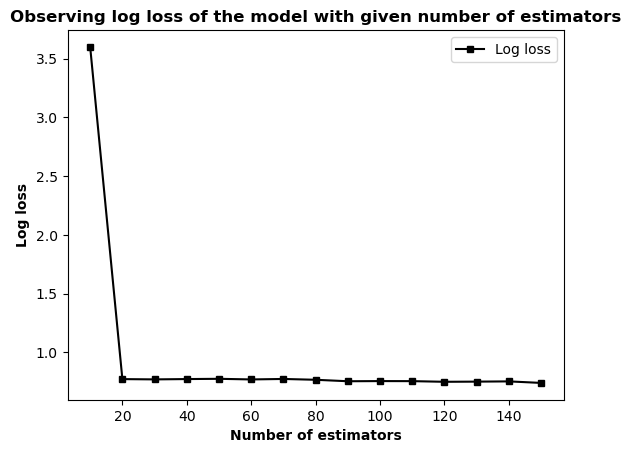

In [222]:
import matplotlib as mpl
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(trees,
        Estimated,
        marker = "s",
        markersize = 5,
        color = "black",
        label = "Log loss")
ax.set_title("Observing log loss of the model with given number of estimators",
       fontweight = "bold")
ax.set_xlabel("Number of estimators", 
              fontweight = "bold")
ax.set_ylabel("Log loss",
              fontweight = "bold")
plt.legend()
plt.show()

In [176]:
#just for exporting logloss for visualization
# llca = pd.DataFrame(Estimated)
# llca.columns = ["log loss comparative advantage"]
# llca.set_index(trees, inplace = True)
# llca.to_csv("llca.csv")

In [223]:
for i, values in enumerate(Estimated):
    print((i+1)*10, values)
print("It appears 150 number of estimators is able to obtain the least log loss")

10 3.598998084883399
20 0.7735706408890612
30 0.7711887952585323
40 0.7739053870929752
50 0.776104230872887
60 0.7707626734832848
70 0.7748394842688601
80 0.767856935486447
90 0.7553689570763511
100 0.7567593128190435
110 0.7562625496949308
120 0.7507355861072341
130 0.7520948429316942
140 0.7541802877597573
150 0.7411297065279278
It appears 150 number of estimators is able to obtain the least log loss


In [224]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 150, 
                            max_features = maxfeatures,
                            max_depth=None, 
                            random_state=0)

rf.fit(x_train_pca, y_train_encoded_df)
y_test_proba_hat = rf.predict_proba(x_test_pca) # note that the proba_hat provides probability estimates across target classes 
                                                # and not hard predictions of a specific target class
Eval_scores = log_loss(y_test_encoded_df, y_test_proba_hat)
print(f"we obtained the log_loss of {round(Eval_scores, 4)} compared to baseline log loss of 0.9217")

d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


we obtained the log_loss of 0.6475 compared to baseline log loss of 0.9217


Baseline log loss = [P1*ln(P1) + P2*ln(P2) +P3*ln(P3) + .......Pn*ln(Pn)], 
where Proportional observations (Pn) = Observation in a given class/Total observations



In [228]:
#Now lets check the features that were most important in defining our model
#Regarding that, one important thing to do is to have the names of the features in the first place
Feature_Importance = rf.feature_importances_
Feature_Importance = pd.DataFrame(Feature_Importance)
Feature_Importance = Feature_Importance.T
Feature_Importance.columns = x_train_pca.columns.to_list() #we are going to have the name of the features through this syntax
Feature_Importance = Feature_Importance.T
Feature_Importance.reset_index(inplace = True)
Feature_Importance.columns = ["Features", "Significance"] #Now naming the columns
Feature_Importance = Feature_Importance.set_index("Features")

In [229]:
Feature_Importance = Feature_Importance.sort_values(ascending= False, by = "Significance")
Feature_Importance = Feature_Importance
Feature_Importance["Proportional Significance"] = Feature_Importance["Significance"]*100
Feature_Importance.to_csv("Feature importance CA.csv")
Feature_Importance

,Significance,Proportional Significance
Features,,
Climate resilience and suitability_No difference,0.163442,16.344211
Climate resilience and suitability_Indigenous crop species,0.155008,15.500805
Climate resilience and suitability_Improved crop species,0.146593,14.659255
Resource Intensity_Improved crop species,0.098288,9.828817
Productivity and storability_Indigenous crop species,0.084738,8.473768
Productivity and storability_Improved crop species,0.080068,8.006776
Productivity and storability_No difference,0.069139,6.913864
Market potential_Improved crop species,0.061822,6.182207
Resource Intensity_Indigenous crop species,0.049408,4.940768


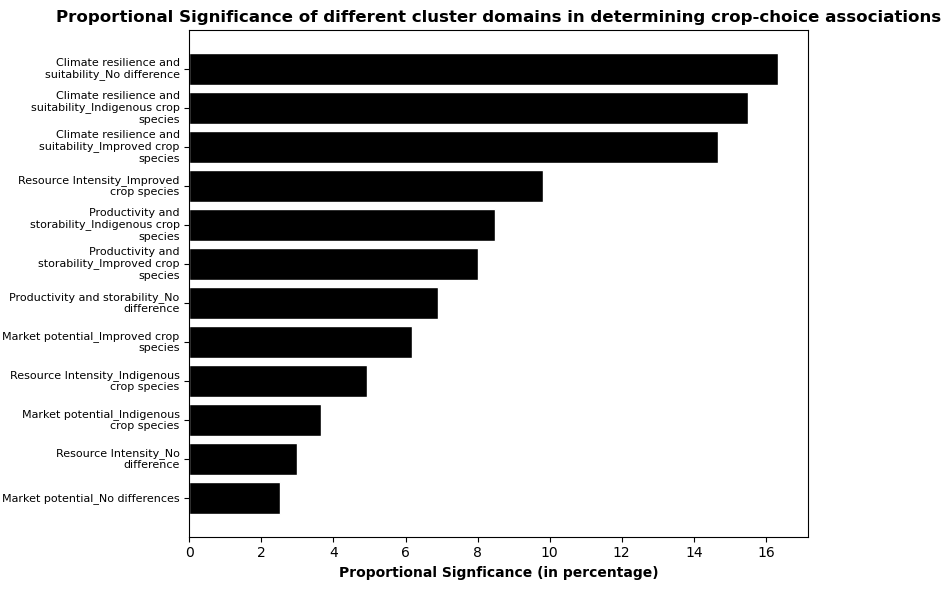

In [334]:
import matplotlib as mpl
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize = (8,6))

ax.barh(Feature_Importance.index,
       Feature_Importance["Proportional Significance"],
       color = "black",
       edgecolor = "white",
       label = "Significance")

ax.invert_yaxis() #for some reason the ascending sorting does not seem to work for barplotting
ax.set_title("Proportional Significance of different cluster domains in determining crop-choice associations",
             fontweight = "bold")
ax.set_xlabel("Proportional Signficance (in percentage)",
              fontweight = "bold")
ax.set_ylabel("Features",
              fontweight = "bold")

yticklabels = ax.get_yticklabels()
for labels in yticklabels:
    labels.set_wrap(True)
    labels.set_fontsize(8)
    labels.set_ha("right")
    labels.set_va("center")

plt.tight_layout()
#plt.subplots_adjust(left=0.35)
plt.show()

In [234]:
#Preparing the Classification report
y_test_hat = rf.predict(x_test_pca) #getting the hard predictions from the random forest model
y_test_hat_labelled = label_encoder.inverse_transform(y_test_hat) # getting original labels of the predictions

from sklearn.metrics import classification_report
print(classification_report(y_test_hat_labelled, y_test))

                                                             precision    recall  f1-score   support

                 Planting of improved species of crops only       0.00      0.00      0.00         0
               Planting of indigenous species of crops only       0.90      0.75      0.82        12
Planting of mix of indigenous and improved species of crops       0.75      0.75      0.75        12

                                                   accuracy                           0.75        24
                                                  macro avg       0.55      0.50      0.52        24
                                               weighted avg       0.83      0.75      0.78        24



d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [255]:
#Generating an illustration of log_loss penalty mechanism 
Prediction_porba = pd.DataFrame(y_test_proba_hat)
Prediction_porba.columns = ["Planting improved crop species only",
                            "Planting indigenous crop species only",
                            "Planting a mix of improved and indigenous crop species"]

Penality_mechanism = pd.merge(Prediction_porba, y_test, left_index = True, right_index = True)
Penality_mechanism.head()


,Planting improved crop species only,Planting indigenous crop species only,Planting a mix of improved and indigenous crop species,Crop Choice
0,0.064444,0.006667,0.928889,Planting of improved species of crops only
2,0.039455,0.175520,0.785025,Planting of mix of indigenous and improved spe...
5,0.012222,0.000000,0.987778,Planting of mix of indigenous and improved spe...
14,0.269688,0.426461,0.303851,Planting of improved species of crops only
18,0.027712,0.858572,0.113716,Planting of mix of indigenous and improved spe...


#### Support Vector Machine

In [241]:
#Now calculating the distance of the predicted target value from the hyper-plane (i.e., decision boundary)
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

Estimated = []
C = [0.01, 0.1, 1.0, 10] # arranging exponential parameters 
for values in C:
    svm = LinearSVC(loss = "hinge",
                    multi_class = "ovr",
                    C = values,
                    dual = True,
                    random_state = 0)
    
    svm.fit(x_train_pca, y_train_encoded_df)

    y_eval_distance = svm.decision_function(x_eval_pca)
    y_eval_distance_df = pd.DataFrame(y_eval_distance)
    y_eval_probs = softmax(y_eval_distance_df, axis = 1) # Now turning raw distance in probabilities using softmax

    Eval_scores = roc_auc_score(y_eval_encoded_df,
                                y_eval_probs,
                                multi_class = "ovr",
                                average = "weighted") # Adjusts for any class size differences in the split
    Estimated.append(Eval_scores)
print(Estimated)    

[np.float64(0.7822702659659181), np.float64(0.7559125656951744), np.float64(0.7522893772893774), np.float64(0.6824534161490682)]


d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please 

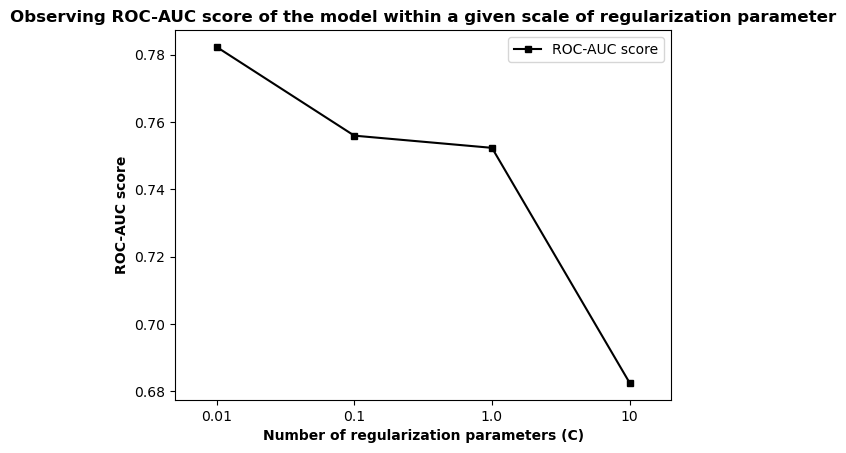

In [242]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(C,
        Estimated,
        marker = "s",
        markersize = 5,
        color = "black",
        label = "ROC-AUC score")

ax.set_title("Observing ROC-AUC score of the model within a given scale of regularization parameter",
             fontweight = "bold")

ax.set_xscale("log")
ax.set_xticks(C)
ax.set_xticklabels(["0.01", "0.1", "1.0", "10"])
ax.minorticks_off()

ax.set_xlim(0.005, 20)
ax.set_xlabel("Number of regularization parameters (C)",
              fontweight = "bold")

ax.set_ylabel("ROC-AUC score",
              fontweight = "bold")
plt.legend()
plt.show()

In [251]:
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

svm = LinearSVC(loss = "hinge",
                multi_class = "ovr",
                C = 0.01,
                dual = True,
                random_state = 0)

svm.fit(x_train_pca, y_train_encoded_df)

y_test_distance = svm.decision_function(x_test_pca)
y_test_distance_df = pd.DataFrame(y_test_distance)
y_test_probs = softmax(y_test_distance_df, axis = 1) # Now turning raw distance in probabilities using softmax

score = roc_auc_score(y_test_encoded_df,
                      y_test_probs,
                      multi_class = "ovr",
                      average = "weighted") # Adjusts for any class size differences in the split
print(f"The accuracy of the estimates of the model is {round(score*100, 3)} percent")

The accuracy of the estimates of the model is 91.843 percent


d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [253]:
#Now producing the classification report 
y_test_hat = svm.predict(x_test_pca) #Retrieving the hard prediction based on the RF model
y_test_hat_labelled = label_encoder.inverse_transform(y_test_hat) #Reverse transform the data for labelling purpose

from sklearn.metrics import classification_report
print(classification_report(y_test_hat_labelled, y_test))
#the accuracy appears to be similar if not slightly less for each target class than the earlier RF model. The model accuracy is also 
# only slightly better that the earlier RF model.

                                                             precision    recall  f1-score   support

                 Planting of improved species of crops only       0.00      0.00      0.00         0
               Planting of indigenous species of crops only       0.90      0.82      0.86        11
Planting of mix of indigenous and improved species of crops       0.92      0.85      0.88        13

                                                   accuracy                           0.83        24
                                                  macro avg       0.61      0.55      0.58        24
                                               weighted avg       0.91      0.83      0.87        24



d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#Now observing the coefficients of each independent variables that built the SVM model 
Feature_Coefficient = svm.coef_
Feature_Coefficient = pd.DataFrame(Feature_Coefficient)
Feature_Coefficient.columns = x_train_pca.columns.to_list()
Feature_Coefficient = Feature_Coefficient.T
Feature_Coefficient.reset_index(inplace = True)
Feature_Coefficient.columns = ["Features",
                               "Improved crop species only",
                               "Indigenous crop specices only",
                               "Mixed planting only"]

Feature_Coefficient.set_index("Features", inplace = True)
Feature_Coefficient

,Improved crop species only,Indigenous crop specices only,Mixed planting only
Features,,,
Resource Intensity_Indigenous crop species,0.027237,-0.136660,0.129332
Resource Intensity_Improved crop species,-0.073073,0.161978,-0.120862
Resource Intensity_No difference,0.070827,-0.130696,0.111516
Climate resilience and suitability_Indigenous crop species,0.024605,0.172555,-0.204300
Climate resilience and suitability_Improved crop species,-0.000200,-0.174555,0.167901
Climate resilience and suitability_No difference,0.003468,-0.147361,0.153447
Productivity and storability_Indigenous crop species,-0.068638,0.185590,-0.144516
Productivity and storability_Improved crop species,0.050218,0.082771,-0.099531
Productivity and storability_No difference,-0.109308,0.150365,-0.110206


In [316]:
Feature_Coefficient.to_csv("FC CA.csv")

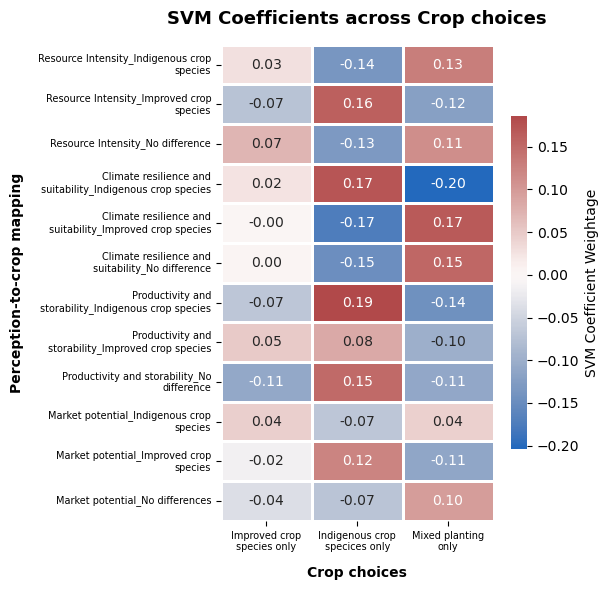

In [336]:
import textwrap
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Wrap Y-axis feature labels (e.g., width=35 characters)
wrapped_y_labels = [textwrap.fill(label, width=35) for label in Feature_Coefficient.index]

# 2. Wrap X-axis column labels (e.g., width=15 characters)
wrapped_x_labels = [textwrap.fill(label, width=15) for label in Feature_Coefficient.columns]

plt.figure(figsize=(6, 6))

# 3. Pass wrapped labels into yticklabels and xticklabels
sns.heatmap(Feature_Coefficient,
            annot=True,
            fmt=".2f",
            cmap="vlag",
            center=0,
            cbar_kws={"label": "SVM Coefficient Weightage",
                      "shrink": 0.7},
            linewidths=0.8,
            linecolor="white",
            xticklabels=wrapped_x_labels,
            yticklabels=wrapped_y_labels,
            square = False)
ax.set_aspect(0.1)
# 4. Rotate labels for cleaner presentation
plt.xticks(rotation=0,
           fontsize=7)  

plt.yticks(rotation=0,
           fontsize=7)  

plt.title("SVM Coefficients across Crop choices",
          fontsize=13,
          pad=15,
          fontweight = "bold")

plt.xlabel("Crop choices",
           fontsize=10,
           labelpad=10,
           fontweight = "bold")

plt.ylabel("Perception-to-crop mapping",
           fontsize=10,
           labelpad=10,
           fontweight = "bold")

plt.tight_layout()
plt.show()

In [263]:
#Observing the encoded labels for reference
labels = label_encoder.classes_ 
for i, values in enumerate(labels):
    print(i, values)

0 Planting of improved species of crops only
1 Planting of indigenous species of crops only
2 Planting of mix of indigenous and improved species of crops
